# Chapter 6: Tracking control and almost-global stability

This notebook reproduces the chapter's examples.

1. The PD law with feedforward on $\mathrm{SO}(3)$, and the fact that its error dynamics forget the reference.
2. The Lyapunov proof: test every inequality at random states, and compare the guaranteed rate with a simulated run.
3. Almost everywhere: the half turns, their unstable direction, and the settling time against the initial angle.
4. The same template on $S^2$.
5. The quadrotor cascade, with and without the attitude feedforward, and the cable-suspended load.
6. Feedback linearization of a 3D pendulum, geometric against Euler angles, over a grid of initial attitudes.

Notation follows the book: $\dot R = R\,\Omega^\wedge$, $\dot q = \omega\times q$,
$e_R = \tfrac12(R_d^\top R - R^\top R_d)^\vee$, $e_\Omega = \Omega - R^\top R_d\,\Omega_d$, $e_q = q_d\times q$.
Only NumPy, SciPy and Matplotlib are needed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

E1, E2, E3 = np.eye(3)
EYE = np.eye(3)
GRAV = 9.81
rng = np.random.default_rng(6)


def hat(v):
    x, y, z = v
    return np.array([[0.0, -z, y], [z, 0.0, -x], [-y, x, 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(w):
    th = np.linalg.norm(w)
    if th < 1e-12:
        return EYE + hat(w)
    K = hat(np.asarray(w) / th)
    return EYE + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def log_so3(R):
    th = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    if th < 1e-9:
        return vee(R - R.T) / 2
    if np.pi - th < 1e-6:
        S = (R + EYE) / 2
        a = np.sqrt(np.clip(np.diag(S), 0, None))
        k = int(np.argmax(a))
        return th * S[:, k] / a[k]
    return th * vee(R - R.T) / (2 * np.sin(th))


def unit(v):
    return np.asarray(v, float) / np.linalg.norm(v)


def tangent(q, v):
    return v - (v @ q) * q


def Psi_R(R, Rd):
    return 0.5 * np.trace(EYE - Rd.T @ R)


def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)


def e_Omega(R, Om, Rd, Omd):
    return Om - R.T @ Rd @ Omd


def C_R(R, Rd):
    return 0.5 * (np.trace(R.T @ Rd) * EYE - R.T @ Rd)


def Psi_q(q, qd):
    return 1 - q @ qd


def e_q(q, qd):
    return np.cross(qd, q)


def e_omega(q, om, omd):
    return om - tangent(q, omd)


def angle_deg(R):
    return np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))


# the vehicle of the chapter (Lee, Leok and McClamroch 2010)
m_Q = 4.34
J = np.diag([0.0820, 0.0845, 0.1377])
Jinv = np.linalg.inv(J)
k_R, k_Om = 8.81, 2.54
k_x, k_v = 16 * m_Q, 5.6 * m_Q
J_min, J_max = J[0, 0], J[2, 2]

## 1. A PD law on the rotation group

$$\tau = -k_R\,e_R - k_\Omega\,e_\Omega + \Omega\times J\Omega - J\big(\Omega\times R^\top R_d\,\Omega_d - R^\top R_d\,\dot\Omega_d\big)$$

gives the closed loop $J\,\dot e_\Omega = -k_R\,e_R - k_\Omega\,e_\Omega$.

In [2]:
def att_torque(R, Om, Rd, Omd, Omd_dot, kR=k_R, kOm=k_Om):
    return (-kR * e_R(R, Rd) - kOm * e_Omega(R, Om, Rd, Omd) + np.cross(Om, J @ Om)
            - J @ (np.cross(Om, R.T @ Rd @ Omd) - R.T @ Rd @ Omd_dot))


def ref_att(t):
    """A tumbling reference: Omegad(t) and its derivative."""
    Omd = np.array([0.6 * np.sin(1.3 * t), 0.5, 0.8 * np.cos(0.7 * t)])
    return Omd, np.array([0.78 * np.cos(1.3 * t), 0.0, -0.56 * np.sin(0.7 * t)])


def att_run(Re0, eOm0, t_f, moving, Rd0=EYE, n=1201):
    def rhs(t, s):
        R, Om, Rd = s[:9].reshape(3, 3), s[9:12], s[12:].reshape(3, 3)
        Omd, Omd_dot = ref_att(t) if moving else (np.zeros(3), np.zeros(3))
        tau = att_torque(R, Om, Rd, Omd, Omd_dot)
        return np.concatenate([(R @ hat(Om)).ravel(), Jinv @ (tau - np.cross(Om, J @ Om)), (Rd @ hat(Omd)).ravel()])

    R0 = Rd0 @ Re0
    Omd0 = ref_att(0.0)[0] if moving else np.zeros(3)
    s0 = np.concatenate([R0.ravel(), eOm0 + R0.T @ Rd0 @ Omd0, Rd0.ravel()])
    ts = np.linspace(0, t_f, n)
    sol = solve_ivp(rhs, [0, t_f], s0, t_eval=ts, rtol=1e-10, atol=1e-12)
    Re = [s[12:].reshape(3, 3).T @ s[:9].reshape(3, 3) for s in sol.y.T]
    eO = [e_Omega(s[:9].reshape(3, 3), s[9:12], s[12:].reshape(3, 3), ref_att(t)[0] if moving else np.zeros(3))
          for t, s in zip(ts, sol.y.T)]
    return ts, np.array(Re), np.array(eO)


Re0 = expm_so3(np.radians(150) * unit([1.0, 2.0, -1.0]))
eOm0 = np.array([0.5, -0.3, 0.4])
ts, Re_mov, eO_mov = att_run(Re0, eOm0, 3.0, moving=True, Rd0=expm_so3([0.4, -1.0, 2.0]))
_, Re_fix, eO_fix = att_run(Re0, eOm0, 3.0, moving=False)
print("largest gap between the error histories, tumbling reference against fixed target:",
      f"{max(np.max(np.abs(Re_mov - Re_fix)), np.max(np.abs(eO_mov - eO_fix))):.1e}")

largest gap between the error histories, tumbling reference against fixed target: 3.0e-10


The error dynamics do not contain $R_d(t)$. From here on we simulate the error system directly.

## 2. The proof, and what it needs

$V = \tfrac12 e_\Omega\cdot J e_\Omega + k_R\Psi_R + c\,e_R\cdot J e_\Omega$, with the three matrices $W_1, W_2, W_3$ of the theorem.

In [3]:
def c_limit(kR, kOm, Jmin, Jmax):
    return min(np.sqrt(kR * Jmin) / Jmax, 4 * kR * kOm / (kOm**2 + 4 * kR * Jmax))


def W_matrices(kR, kOm, Jmin, Jmax, c, Psi_max):
    W1 = 0.5 * np.array([[kR, -c * Jmax], [-c * Jmax, Jmin]])
    W2 = 0.5 * np.array([[2 * kR / (2 - Psi_max), c * Jmax], [c * Jmax, Jmax]])
    W3 = np.array([[c * kR, -c * kOm / 2], [-c * kOm / 2, kOm - c * Jmax]])
    return W1, W2, W3


worst = dict(lower=-np.inf, upper=-np.inf, rate=-np.inf)
for _ in range(3000):
    Jd = np.sort(0.01 + rng.random(3))
    U = expm_so3(3 * rng.normal(size=3))
    Jr = U @ np.diag(Jd) @ U.T
    kR, kOm = 0.1 + 20 * rng.random(), 0.05 + 5 * rng.random()
    c = c_limit(kR, kOm, Jd[0], Jd[2]) * rng.uniform(0.01, 0.99)
    Psi_max = 2 * rng.uniform(0.01, 0.999)
    R = expm_so3(np.arccos(1 - Psi_max * rng.random()) * unit(rng.normal(size=3)))
    eO = 3 * rng.random() * rng.normal(size=3)
    e_Rv, Psi, C = e_R(R, EYE), Psi_R(R, EYE), C_R(R, EYE)
    z = np.array([np.linalg.norm(e_Rv), np.linalg.norm(eO)])
    W1, W2, W3 = W_matrices(kR, kOm, Jd[0], Jd[2], c, Psi_max)
    V = 0.5 * eO @ Jr @ eO + kR * Psi + c * e_Rv @ Jr @ eO
    V_dot = -kOm * eO @ eO + c * eO @ C.T @ Jr @ eO - c * kR * e_Rv @ e_Rv - c * kOm * e_Rv @ eO
    worst["lower"] = max(worst["lower"], z @ W1 @ z - V)
    worst["upper"] = max(worst["upper"], V - z @ W2 @ z)
    worst["rate"] = max(worst["rate"], V_dot + z @ W3 @ z)
print("largest violation of  z'W1 z <= V, V <= z'W2 z, V_dot <= -z'W3 z :", {k: f"{v:.1e}" for k, v in worst.items()})

largest violation of  z'W1 z <= V, V <= z'W2 z, V_dot <= -z'W3 z : {'lower': '-2.6e-03', 'upper': '-3.9e-03', 'rate': '-4.9e-05'}


V0(0) = 16.46 < 2 k_R = 17.62,  Psi_max = 1.869
limits on c: 6.17 and 7.92;  best c = 0.46
guaranteed rate 0.034 1/s,  measured rate 8.0 1/s


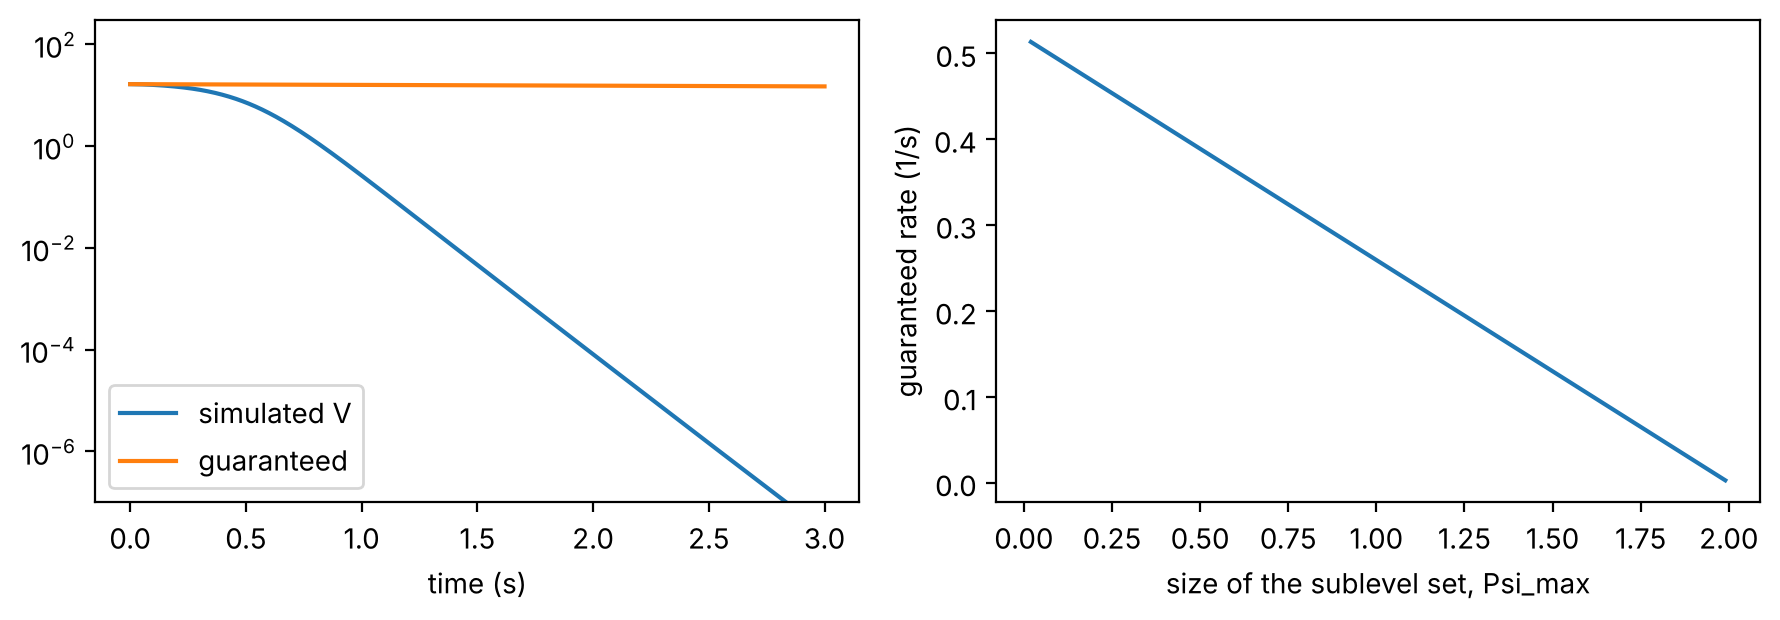

In [4]:
def error_run(Re0, eOm0, t_f, n=1201, law="trace"):
    def rhs(t, s):
        Re, eO = s[:9].reshape(3, 3), s[9:]
        e = e_R(Re, EYE) if law == "trace" else log_so3(Re)
        return np.concatenate([(Re @ hat(eO)).ravel(), Jinv @ (-k_R * e - k_Om * eO)])

    ts = np.linspace(0, t_f, n)
    sol = solve_ivp(rhs, [0, t_f], np.concatenate([Re0.ravel(), eOm0]), t_eval=ts, rtol=1e-9, atol=1e-11)
    return ts, sol.y[:9].T.reshape(-1, 3, 3), sol.y[9:].T


def best_rate(Psi_max):
    best = (0.0, 0.0)
    for c in np.linspace(0.002, 0.998, 499) * c_limit(k_R, k_Om, J_min, J_max):
        _, W2, W3 = W_matrices(k_R, k_Om, J_min, J_max, c, Psi_max)
        best = max(best, (np.linalg.eigvalsh(W3)[0] / np.linalg.eigvalsh(W2)[-1], c))
    return best


ts, Res, eOs = error_run(Re0, eOm0, 3.0)
V0 = np.array([0.5 * eO @ J @ eO + k_R * Psi_R(R, EYE) for R, eO in zip(Res, eOs)])
Psi_max = V0[0] / k_R
gamma, c = best_rate(Psi_max)
V = np.array([0.5 * eO @ J @ eO + k_R * Psi_R(R, EYE) + c * e_R(R, EYE) @ J @ eO for R, eO in zip(Res, eOs)])
measured = -np.polyfit(ts[ts > 1.5], np.log(V[ts > 1.5]), 1)[0]
print(f"V0(0) = {V0[0]:.2f} < 2 k_R = {2 * k_R:.2f},  Psi_max = {Psi_max:.3f}")
print(f"limits on c: {np.sqrt(k_R * J_min) / J_max:.2f} and {4 * k_R * k_Om / (k_Om**2 + 4 * k_R * J_max):.2f};  best c = {c:.2f}")
print(f"guaranteed rate {gamma:.3f} 1/s,  measured rate {measured:.1f} 1/s")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].semilogy(ts, V, label="simulated V")
ax[0].semilogy(ts, V[0] * np.exp(-gamma * ts), label="guaranteed")
ax[0].set_xlabel("time (s)")
ax[0].set_ylim(1e-7, 300)
ax[0].legend()
psis = np.linspace(0.02, 1.99, 60)
ax[1].plot(psis, [best_rate(p)[0] for p in psis])
ax[1].set_xlabel("size of the sublevel set, Psi_max")
ax[1].set_ylabel("guaranteed rate (1/s)")
plt.tight_layout()
plt.show()

## 3. Almost everywhere

Near a half turn about $a$, $e_R \approx -(a\,a^\top)\,\eta$. The linearization has one unstable eigenvalue.

axis [1. 0. 0.]: unstable 1, zero 2, stable 3, growth rate 3.15 1/s
axis [0. 1. 0.]: unstable 1, zero 2, stable 3, growth rate 3.14 1/s
axis [0. 0. 1.]: unstable 1, zero 2, stable 3, growth rate 2.99 1/s
axis [0.58 0.58 0.58]: unstable 1, zero 2, stable 3, growth rate 3.09 1/s


from 179.000 deg about e1: 2.34 s
from 179.900 deg about e1: 3.07 s
from 179.990 deg about e1: 3.80 s
from 179.999 deg about e1: 4.54 s


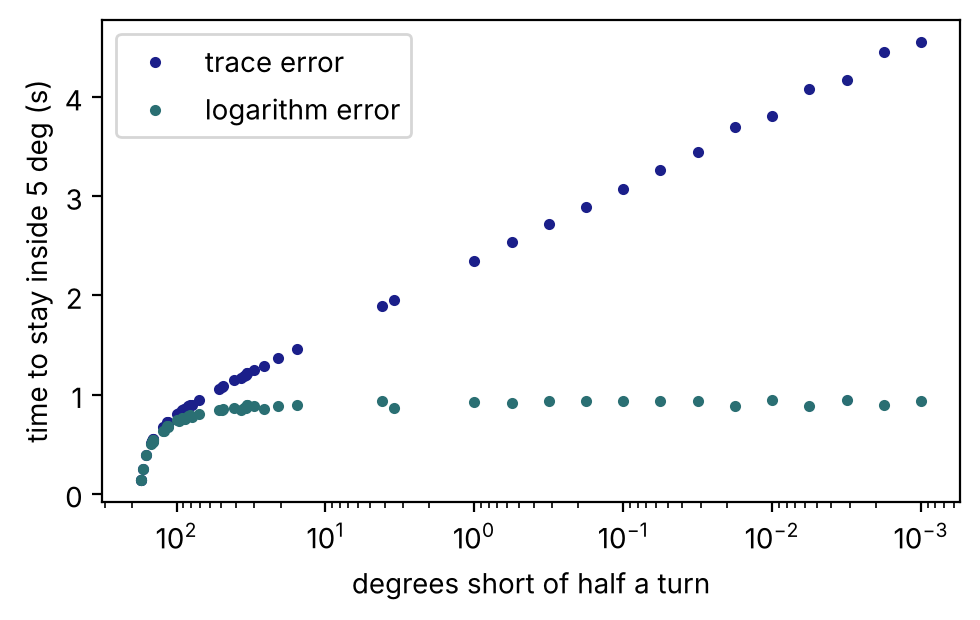

In [5]:
def half_turn_eigenvalues(a):
    A = np.block([[np.zeros((3, 3)), EYE], [Jinv @ (k_R * np.outer(a, a)), -k_Om * Jinv]])
    return np.linalg.eigvals(A)


for a in (E1, E2, E3, unit([1, 1, 1])):
    ev = half_turn_eigenvalues(a)
    print(f"axis {np.round(a, 2)}: unstable {np.sum(ev.real > 1e-7)}, zero {np.sum(np.abs(ev) < 1e-7)}, "
          f"stable {np.sum(ev.real < -1e-7)}, growth rate {ev.real.max():.2f} 1/s")


def settle_time(Re0, law="trace", t_f=14.0):
    ts, Rs, _ = error_run(Re0, np.zeros(3), t_f, n=2801, law=law)
    out = np.nonzero(np.array([angle_deg(R) for R in Rs]) > 5)[0]
    return 0.0 if not len(out) else ts[min(out[-1] + 1, len(ts) - 1)]


gaps = np.concatenate([180 - rng.uniform(5, 179, 40), np.logspace(-3, 0, 13)])       # degrees short of half a turn
axes = [unit(rng.normal(size=3)) for _ in gaps]
t_trace = [settle_time(expm_so3(np.radians(180 - g) * a)) for g, a in zip(gaps, axes)]
t_log = [settle_time(expm_so3(np.radians(180 - g) * a), law="log") for g, a in zip(gaps, axes)]
for k in range(4):
    print(f"from {180 - 10.0**-k:.3f} deg about e1: {settle_time(expm_so3(np.radians(180 - 10.0**-k) * E1)):.2f} s")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogx(gaps, t_trace, "o", ms=3, color="#1b1f8a", label="trace error")
ax.semilogx(gaps, t_log, "o", ms=3, color="#2a6f73", label="logarithm error")
ax.invert_xaxis()
ax.set_xlabel("degrees short of half a turn")
ax.set_ylabel("time to stay inside 5 deg (s)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. The same template on the sphere

Spherical pendulum with a force on the bob, $m l^2\dot\omega = -m g l\,q\times e_3 + l\,q\times F$. The law is
$$\dot\omega = (I - q q^\top)\dot\omega_d - (q\cdot\omega_d)\,\dot q - k_q e_q - k_\omega e_\omega, \qquad F = m g\,e_3 + m l\,\dot\omega\times q .$$

start  60.0 deg: inside 5 deg after 0.74 s, V0 never increases: True


start 170.0 deg: inside 5 deg after 1.97 s, V0 never increases: True


start 179.9 deg: inside 5 deg after 4.16 s, V0 never increases: True


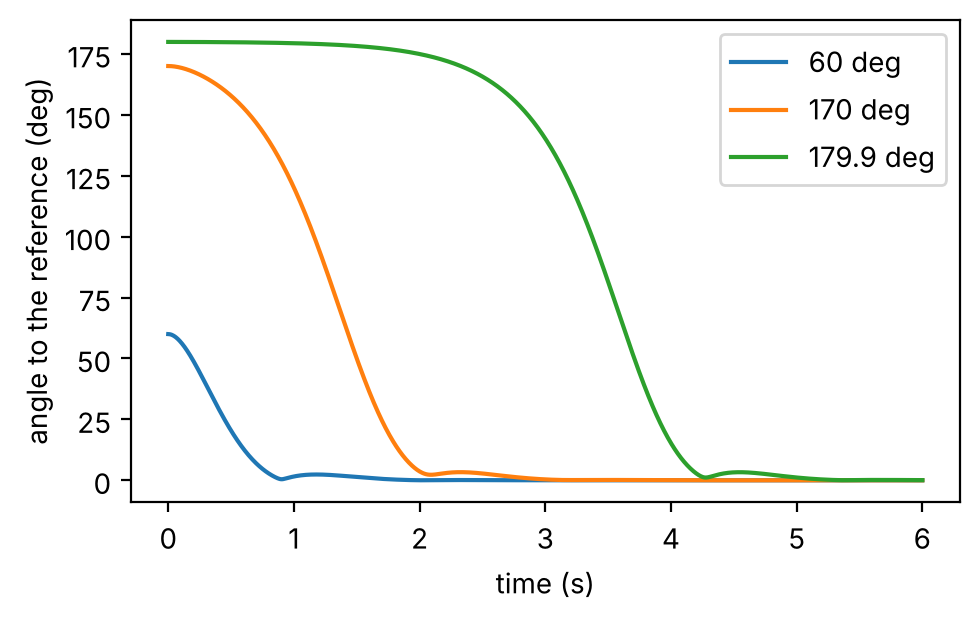

In [6]:
m_p, l_p = 1.0, 1.0
k_q, k_om = 16.0, 5.6
CONE, W_REF = np.radians(35), 1.2


def ref_s2(t):
    c, s = np.cos(W_REF * t), np.sin(W_REF * t)
    qd = np.array([np.sin(CONE) * c, np.sin(CONE) * s, np.cos(CONE)])
    qd1 = np.sin(CONE) * W_REF * np.array([-s, c, 0])
    qd2 = -np.sin(CONE) * W_REF**2 * np.array([c, s, 0])
    return qd, np.cross(qd, qd1), np.cross(qd, qd2)


def s2_force(q, om, qd, omd, omd_dot):
    om_dot = tangent(q, omd_dot) - (q @ omd) * np.cross(om, q) - k_q * e_q(q, qd) - k_om * e_omega(q, om, omd)
    return m_p * GRAV * E3 + m_p * l_p * np.cross(om_dot, q)


def s2_rhs(t, s):
    q, om = s[:3], s[3:]
    F = s2_force(q, om, *ref_s2(t))
    return np.concatenate([np.cross(om, q), (-m_p * GRAV * l_p * np.cross(q, E3) + l_p * np.cross(q, F)) / (m_p * l_p**2)])


fig, ax = plt.subplots(figsize=(5, 3.2))
for ang in (60.0, 170.0, 179.9):
    qd0, omd0, _ = ref_s2(0.0)
    q0 = expm_so3(np.radians(ang) * unit(np.cross(qd0, E2))) @ qd0
    sol = solve_ivp(s2_rhs, [0, 6], np.concatenate([q0, tangent(q0, omd0)]), t_eval=np.linspace(0, 6, 1201), rtol=1e-10, atol=1e-12)
    err = np.degrees(np.arccos(np.clip([q @ ref_s2(t)[0] for t, q in zip(sol.t, sol.y[:3].T)], -1, 1)))
    V0 = [0.5 * e_omega(s[:3], s[3:], ref_s2(t)[1]) @ e_omega(s[:3], s[3:], ref_s2(t)[1]) + k_q * Psi_q(s[:3], ref_s2(t)[0])
          for t, s in zip(sol.t, sol.y.T)]
    print(f"start {ang:5.1f} deg: inside 5 deg after {sol.t[np.nonzero(err > 5)[0][-1] + 1]:.2f} s, "
          f"V0 never increases: {np.max(np.diff(V0)) < 1e-9}")
    ax.plot(sol.t, err, label=f"{ang:g} deg")
ax.set_xlabel("time (s)")
ax.set_ylabel("angle to the reference (deg)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Cascades

Quadrotor: $F_d = -k_x (x - x_d) - k_v (v - \dot x_d) + m g\,e_3 + m\ddot x_d$, $f = F_d\cdot R e_3$, and $R_d$ built from $F_d$ and the heading.
`Rd_derivs` returns $\Omega_d$ and $\dot\Omega_d$ from $F_d$, $\dot F_d$, $\ddot F_d$, which the model supplies in closed form.

inverted start: right side up after 0.30 s, peak position error 1.55 m, within 5 cm after 1.94 s


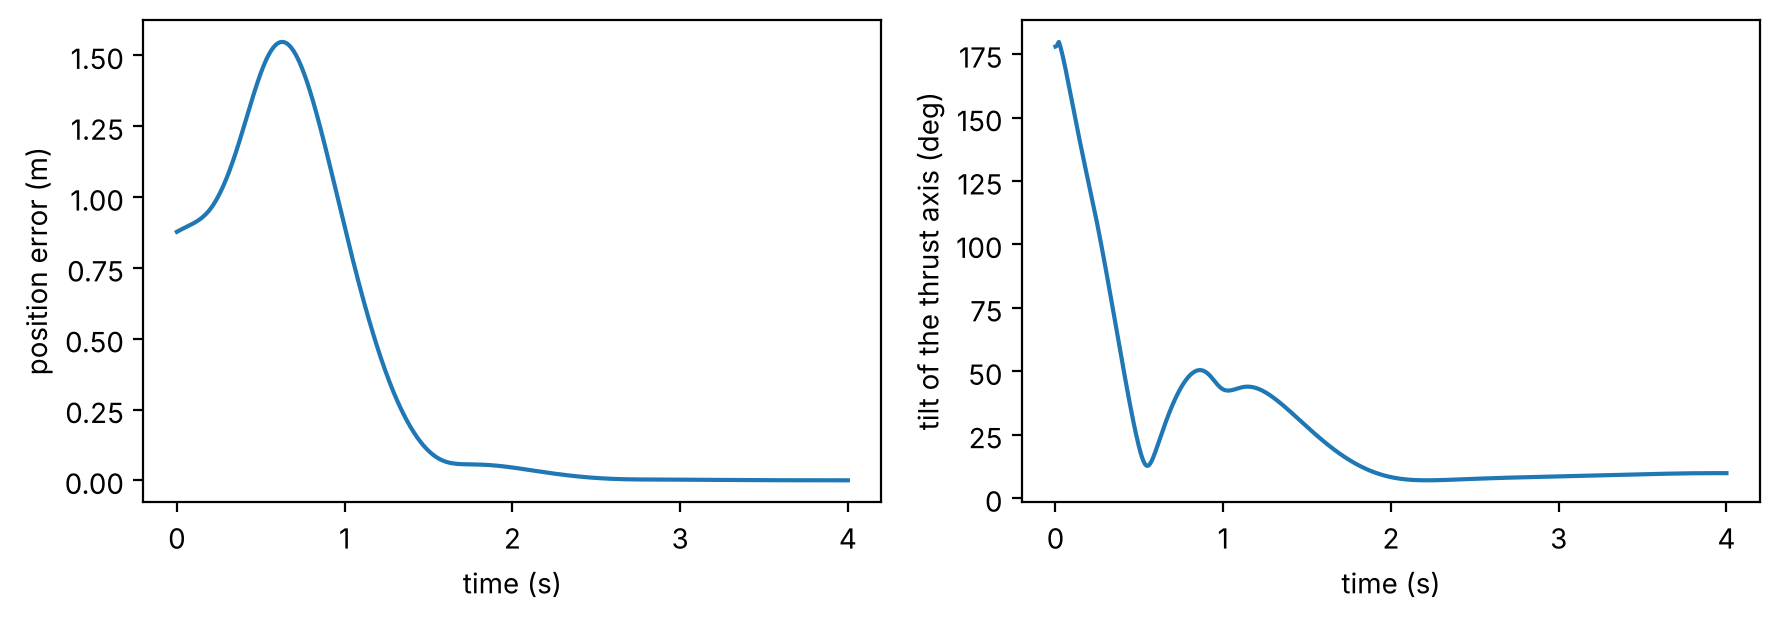

In [7]:
def ref_pos(t, w=1.0, r=1.5):
    c, s, c2, s2 = np.cos(w * t), np.sin(w * t), np.cos(2 * w * t), np.sin(2 * w * t)
    x = np.array([r * c, r * s, 0.3 * s2])
    v = np.array([-r * w * s, r * w * c, 0.6 * w * c2])
    a = np.array([-r * w**2 * c, -r * w**2 * s, -1.2 * w**2 * s2])
    j = np.array([r * w**3 * s, -r * w**3 * c, -2.4 * w**3 * c2])
    sn = np.array([r * w**4 * c, r * w**4 * s, 4.8 * w**4 * s2])
    psi = w * t + np.pi / 2
    hd = np.array([np.cos(psi), np.sin(psi), 0.0])
    return x, v, a, j, sn, hd, w * np.array([-np.sin(psi), np.cos(psi), 0.0]), -w**2 * hd


def Rd_from(F, hd):
    b3 = unit(F)
    b2 = unit(np.cross(b3, hd))
    return np.column_stack([np.cross(b2, b3), b2, b3])


def Rd_derivs(F, F1, F2, hd, hd1, hd2, d=1e-4):
    def g(s):
        return Rd_from(F + s * F1 + 0.5 * s * s * F2, hd + s * hd1 + 0.5 * s * s * hd2)

    R0, Rp, Rm = g(0.0), g(d), g(-d)
    Wd = R0.T @ (Rp - Rm) / (2 * d)
    Omd = vee(0.5 * (Wd - Wd.T))
    A2 = R0.T @ (Rp - 2 * R0 + Rm) / d**2 - hat(Omd) @ hat(Omd)
    return R0, Omd, vee(0.5 * (A2 - A2.T))


def quad_ctrl(t, x, v, R, Om, feedforward=True, kappa=1.0):
    xd, vd, ad, jd, sd, hd, hd1, hd2 = ref_pos(t)
    Fd = -k_x * (x - xd) - k_v * (v - vd) + m_Q * GRAV * E3 + m_Q * ad
    b3 = R @ E3
    f = max(Fd @ b3, 0.0)                                       # rotors cannot pull
    on = f > 0
    ev1 = f * b3 / m_Q - GRAV * E3 - ad
    F1 = -k_x * (v - vd) - k_v * ev1 + m_Q * jd
    b3_dot = R @ np.cross(Om, E3)
    f1 = (F1 @ b3 + Fd @ b3_dot) if on else 0.0
    F2 = -k_x * ev1 - k_v * ((f1 * b3 + f * b3_dot) / m_Q - jd) + m_Q * sd
    Rd, Omd, Omd_dot = Rd_derivs(Fd, F1, F2, hd, hd1, hd2)
    if not feedforward:
        Omd, Omd_dot = np.zeros(3), np.zeros(3)
    return f, att_torque(R, Om, Rd, Omd, Omd_dot, kappa**2 * k_R, kappa * k_Om), Rd


def quad_run(x0, v0, R0, t_f, feedforward=True, kappa=1.0, n=1001, stop=5.0):
    def rhs(t, s):
        x, v, R, Om = s[:3], s[3:6], s[6:15].reshape(3, 3), s[15:18]
        f, tau, _ = quad_ctrl(t, x, v, R, Om, feedforward, kappa)
        return np.concatenate([v, f * R @ E3 / m_Q - GRAV * E3, (R @ hat(Om)).ravel(), Jinv @ (tau - np.cross(Om, J @ Om))])

    def lost(t, s):
        return stop - np.linalg.norm(s[:3] - ref_pos(t)[0])
    lost.terminal = True
    sol = solve_ivp(rhs, [0, t_f], np.concatenate([x0, v0, R0.ravel(), np.zeros(3)]), t_eval=np.linspace(0, t_f, n),
                    rtol=1e-8, atol=1e-10, max_step=0.01, events=lost)
    return sol.t, sol.y.T


x0 = ref_pos(0)[0] + np.array([0.6, -0.4, 0.5])
t_i, S_i = quad_run(x0, np.zeros(3), expm_so3(np.pi / 2 * E3) @ expm_so3(np.radians(178) * E1), 4.0)
err = np.array([np.linalg.norm(s[:3] - ref_pos(t)[0]) for t, s in zip(t_i, S_i)])
tilt = np.degrees(np.arccos(np.clip(S_i[:, 14], -1, 1)))
print(f"inverted start: right side up after {t_i[np.nonzero(tilt > 90)[0][-1] + 1]:.2f} s, peak position error {err.max():.2f} m, "
      f"within 5 cm after {t_i[np.nonzero(err > 0.05)[0][-1] + 1]:.2f} s")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(t_i, err)
ax[0].set_xlabel("time (s)")
ax[0].set_ylabel("position error (m)")
ax[1].plot(t_i, tilt)
ax[1].set_xlabel("time (s)")
ax[1].set_ylabel("tilt of the thrust axis (deg)")
plt.tight_layout()
plt.show()

### The feedforward is doing the separating

Drop $\Omega_d$ and $\dot\Omega_d$, and speed the attitude loop up by $\kappa$ (gains $\kappa^2 k_R$, $\kappa k_\Omega$).

In [8]:
x0s = ref_pos(0)[0] + np.array([0.05, 0.0, 0.0])
for ff, kappa in ((True, 1.0), (False, 1.0), (False, 2.0), (False, 4.0)):
    t_, S_ = quad_run(x0s, ref_pos(0)[1], expm_so3(np.pi / 2 * E3), 20.0, feedforward=ff, kappa=kappa)
    e_ = np.array([np.linalg.norm(s[:3] - ref_pos(t)[0]) for t, s in zip(t_, S_)])
    tail = f"largest error in the last 5 s: {e_[t_ > 15].max():.1e} m" if t_[-1] > 19.9 else f"diverged: error passed 5 m at {t_[-1]:.1f} s"
    print(f"feedforward {'exact' if ff else 'zero ':5s}  kappa = {kappa:g}:  {tail}")

feedforward exact  kappa = 1:  largest error in the last 5 s: 3.4e-11 m


feedforward zero   kappa = 1:  diverged: error passed 5 m at 14.6 s


feedforward zero   kappa = 2:  largest error in the last 5 s: 1.4e-02 m


feedforward zero   kappa = 4:  largest error in the last 5 s: 7.0e-03 m


### One more layer: the cable-suspended load

$F_L = -k_x (x_L - x_d) - k_v (v_L - \dot x_d) + (m_Q + m_L)(\ddot x_d + g\,e_3)$, the cable is asked to point along
$q_d = -(F_L + m_Q l\|\dot q\|^2 q)/\|\cdot\|$, and the thrust vector is
$(F_L\cdot q + m_Q l\|\dot q\|^2)\,q + m_Q l\; q\times(-k_q e_q - k_\omega e_\omega)$. No feedforward for the inner loops.

kappa = 1: diverged, error passed 20 m at 7.4 s


kappa = 2: load error 1.1e-03 m, swing 0.09 deg at 12 s


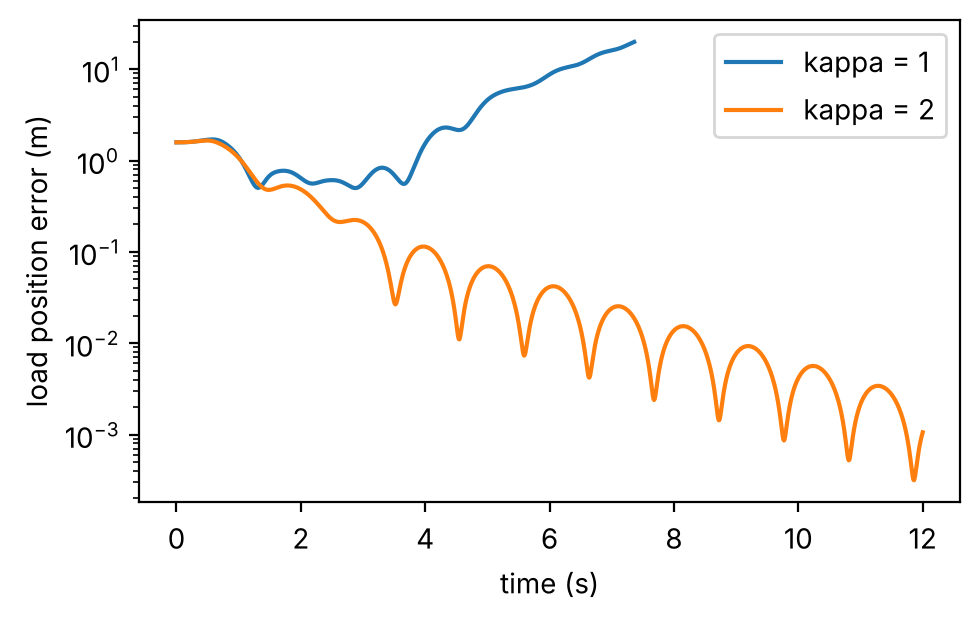

In [9]:
m_L, l_c = 0.5, 1.0
kxL, kvL, kqL, komL = 4.0 * (m_Q + m_L), 2.8 * (m_Q + m_L), 25.0, 7.0


def load_force(x, v, q, om, xd):
    A = -kxL * (x - xd) - kvL * v + (m_Q + m_L) * GRAV * E3 + m_Q * l_c * (om @ om) * q
    qd = -unit(A)
    return (A @ q) * q + m_Q * l_c * np.cross(q, -kqL * e_q(q, qd) - komL * om)


def load_run(kappa, t_f=12.0):
    xd = np.array([1.5, 0.0, 0.5])

    def rhs(t, s):
        x, v, q, om, R, Om = s[:3], s[3:6], s[6:9], s[9:12], s[12:21].reshape(3, 3), s[21:]
        F = load_force(x, v, q, om, xd)
        u = max(F @ (R @ E3), 0.0) * R @ E3
        tau = att_torque(R, Om, Rd_from(F, E1), np.zeros(3), np.zeros(3), kappa**2 * k_R, kappa * k_Om)
        return np.concatenate([v, ((q @ u) - m_Q * l_c * (om @ om)) * q / (m_Q + m_L) - GRAV * E3, np.cross(om, q),
                               -np.cross(q, u) / (m_Q * l_c), (R @ hat(Om)).ravel(), Jinv @ (tau - np.cross(Om, J @ Om))])

    def lost(t, s):
        return 20.0 - np.linalg.norm(s[:3] - xd)
    lost.terminal = True
    q0 = expm_so3(np.radians(40) * E1) @ (-E3)
    s0 = np.concatenate([np.zeros(6), q0, np.zeros(3), EYE.ravel(), np.zeros(3)])
    sol = solve_ivp(rhs, [0, t_f], s0, t_eval=np.linspace(0, t_f, 1201), rtol=1e-8, atol=1e-10, max_step=0.01, events=lost)
    return sol.t, np.linalg.norm(sol.y[:3].T - xd, axis=1), np.degrees(np.arccos(np.clip(-sol.y[8], -1, 1)))


fig, ax = plt.subplots(figsize=(5, 3.2))
for kappa in (1.0, 2.0):
    t_l, e_l, swing = load_run(kappa)
    print(f"kappa = {kappa:g}: " + (f"load error {e_l[-1]:.1e} m, swing {swing[-1]:.2f} deg at 12 s" if t_l[-1] > 11.9
                                   else f"diverged, error passed 20 m at {t_l[-1]:.1f} s"))
    ax.semilogy(t_l, e_l, label=f"kappa = {kappa:g}")
ax.set_xlabel("time (s)")
ax.set_ylabel("load position error (m)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. The same law as feedback linearization

A 3D pendulum, $J\dot\Omega + \Omega\times J\Omega = m g\,(R^\top e_3)\times\rho + \tau$, stabilized at the hanging attitude two ways:
the geometric law ($\dot\Omega = -K_p e_R - K_d\Omega$) and the Euler-angle law ($\ddot\Theta = -K_p\Theta - K_d\dot\Theta$).

In [10]:
m_3, rho_3, J_3 = 1.0, np.array([0.0, 0.0, -0.5]), np.diag([0.1625, 0.1625, 0.01])
J3inv = np.linalg.inv(J_3)
K_P, K_D = 100.0, 20.0


def Rz(a):
    return expm_so3(a * E3)


def Ry(a):
    return expm_so3(a * E2)


def Rx(a):
    return expm_so3(a * E1)


def grav_3(R):
    return m_3 * GRAV * np.cross(R.T @ E3, rho_3)


def euler_zyx(R):
    return np.array([np.arctan2(R[1, 0], R[0, 0]), -np.arcsin(np.clip(R[2, 0], -1, 1)), np.arctan2(R[2, 1], R[2, 2])])


def E_mat(th, ph):
    return np.array([[-np.sin(th), 0, 1], [np.cos(th) * np.sin(ph), np.cos(ph), 0], [np.cos(th) * np.cos(ph), -np.sin(ph), 0]])


def E_dot(th, ph, th1, ph1):
    d_th = np.array([[-np.cos(th), 0, 0], [-np.sin(th) * np.sin(ph), 0, 0], [-np.sin(th) * np.cos(ph), 0, 0]])
    d_ph = np.array([[0, 0, 0], [np.cos(th) * np.cos(ph), -np.sin(ph), 0], [-np.cos(th) * np.sin(ph), -np.cos(ph), 0]])
    return d_th * th1 + d_ph * ph1


def tau_geo(R, Om):
    return J_3 @ (-K_P * e_R(R, EYE) - K_D * Om) + np.cross(Om, J_3 @ Om) - grav_3(R)


def tau_euler(R, Om):
    Th = euler_zyx(R)
    if abs(np.cos(Th[1])) < 1e-9:
        return np.full(3, np.nan)                               # E has no inverse
    Em = E_mat(Th[1], Th[2])
    Th1 = np.linalg.solve(Em, Om)
    return J_3 @ (Em @ (-K_P * Th - K_D * Th1) + E_dot(Th[1], Th[2], Th1[1], Th1[2]) @ Th1) + np.cross(Om, J_3 @ Om) - grav_3(R)


def fl_run(R0, Om0, law, t_f=3.0):
    if not np.all(np.isfinite(law(R0, Om0))):
        return np.nan, np.inf

    def rhs(t, s):
        R, Om = s[:9].reshape(3, 3), s[9:12]
        return np.concatenate([(R @ hat(Om)).ravel(), J3inv @ (law(R, Om) + grav_3(R) - np.cross(Om, J_3 @ Om))])

    sol = solve_ivp(rhs, [0, t_f], np.concatenate([R0.ravel(), Om0]), t_eval=np.linspace(0, t_f, 601), rtol=1e-7, atol=1e-9)
    peak = max(np.linalg.norm(law(s[:9].reshape(3, 3), s[9:12])) for s in sol.y.T)
    return Psi_R(sol.y[:9, -1].reshape(3, 3), EYE), peak


grid = np.radians(np.arange(-180, 181, 45))
starts = []
for ps in grid:
    for th in grid:
        for ph in grid:
            Rg = Rz(ps) @ Ry(th) @ Rx(ph)
            if not any(np.allclose(Rg, Q, atol=1e-9) for Q in starts):
                starts.append(Rg)
res_g = np.array([fl_run(Rg, np.zeros(3), tau_geo) for Rg in starts])
res_e = np.array([fl_run(Rg, np.zeros(3), tau_euler) for Rg in starts])
ok_g, ok_e = res_g[:, 0] < 1e-3, res_e[:, 0] < 1e-3
half = np.array([abs(np.trace(Rg) + 1) < 1e-9 for Rg in starts])
both = ok_g & ok_e & (res_g[:, 1] > 1e-9)
print(f"{len(grid)**3} labels, {len(starts)} distinct attitudes, {half.sum()} of them half turns")
print(f"Euler law: undefined at {np.isnan(res_e[:, 0]).sum()}, converges from {ok_e.sum()}")
print(f"geometric law: converges from {ok_g.sum()}; the starts where it stays are exactly the half turns: {np.array_equal(~ok_g, half)}")
print(f"median peak torque where both converge: Euler {np.median(res_e[both, 1]):.1f} N·m, geometric {np.median(res_g[both, 1]):.1f} N·m")
for pitch in (60.0, 89.9, 89.99):
    Rg, Om0 = Ry(np.radians(pitch)) @ Rx(0.3), np.array([1.0, -1.0, 1.0])
    print(f"pitch {pitch:6.2f} deg with a body rate of (1, -1, 1) rad/s: Euler asks {np.linalg.norm(tau_euler(Rg, Om0)):7.1f} N·m, "
          f"geometric {np.linalg.norm(tau_geo(Rg, Om0)):.1f} N·m")

729 labels, 208 distinct attitudes, 29 of them half turns
Euler law: undefined at 16, converges from 192
geometric law: converges from 179; the starts where it stays are exactly the half turns: True
median peak torque where both converge: Euler 28.7 N·m, geometric 7.5 N·m
pitch  60.00 deg with a body rate of (1, -1, 1) rad/s: Euler asks    10.8 N·m, geometric 8.5 N·m
pitch  89.90 deg with a body rate of (1, -1, 1) rad/s: Euler asks    69.2 N·m, geometric 9.4 N·m
pitch  89.99 deg with a body rate of (1, -1, 1) rad/s: Euler asks   829.7 N·m, geometric 9.4 N·m


## Starting points for the exercises

- **Guaranteed rate against $c$.** `W_matrices` and `c_limit` give the rate for any $c$. Plot it for $\Psi_{\max} = 1$, then redo the bounds for the cross term $c\,e_R\cdot e_\Omega$.
- **The rim.** `half_turn_eigenvalues(a)` returns the six eigenvalues at a half turn about `a`. Scan `a` over the sphere.
- **The sphere.** Change `ref_s2` to a reference that spins about an axis close to `q`, and compare convergence.
- **Feedforward.** `quad_run(..., feedforward=False, kappa=...)` reproduces the Pitfall. Bisect on `kappa`.
- **The grid.** Replace `e_R(R, EYE)` by `log_so3(R)` in `tau_geo`, or shift `grid` by one degree, and rerun the last cell.
- **The load.** Lower `kqL` in `load_force` until `load_run(2.0)` fails.

In [11]:
def rate_for(c, Psi_max=1.0):
    _, W2, W3 = W_matrices(k_R, k_Om, J_min, J_max, c, Psi_max)
    return np.linalg.eigvalsh(W3)[0] / np.linalg.eigvalsh(W2)[-1]


cs = np.linspace(0.01, 0.99, 99) * c_limit(k_R, k_Om, J_min, J_max)
print(f"best guaranteed rate for Psi_max = 1: {max(rate_for(c) for c in cs):.3f} 1/s")

best guaranteed rate for Psi_max = 1: 0.259 1/s
